In [38]:
import pandas as pd
import numpy as np
df = pd.read_csv("/content/Data_FIFA.csv")
df.info()
df.describe()
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54600 entries, 0 to 54599
Data columns (total 75 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   player_id                 54600 non-null  object 
 1   player_name               54600 non-null  object 
 2   age                       54600 non-null  int64  
 3   nationality               54600 non-null  object 
 4   team                      54600 non-null  object 
 5   jersey_number             54600 non-null  int64  
 6   position                  54600 non-null  object 
 7   height_cm                 54600 non-null  int64  
 8   weight_kg                 54600 non-null  int64  
 9   preferred_foot            54600 non-null  object 
 10  club_name                 54600 non-null  object 
 11  market_value_eur          54600 non-null  int64  
 12  match_id                  54600 non-null  object 
 13  match_date                54600 non-null  object 
 14  stadiu

,player_id,player_name,age,nationality,team,jersey_number,position,height_cm,weight_kg,preferred_foot,...,possession_impact,pressure_resistance,creativity_score,consistency_score,clutch_performance_score,total_goals_tournament,total_assists_tournament,total_minutes_tournament,player_of_match_awards,tournament_rating
0,P00055,Rodri Fati,26,Spanish,Spain,3,Goalkeeper,195,75,Left,...,1.1,44.2,55.9,42.0,51.8,0,0,242,0,5.8
1,P00070,Ansu Le Normand,19,Spanish,Spain,18,Midfielder,178,75,Right,...,3.5,38.2,43.7,31.1,52.7,0,3,342,0,5.5
2,P00066,Gavi Ramos,18,Spanish,Spain,14,Midfielder,177,72,Left,...,15.3,99.0,99.0,83.4,54.8,1,1,245,0,8.4
3,P00073,Pedro Cubarsi,20,Spanish,Spain,21,Forward,182,74,Right,...,1.2,19.8,42.3,40.9,78.5,5,3,422,0,6.7
4,P00059,Alvaro Oyarzabal,23,Spanish,Spain,7,Defender,191,81,Left,...,6.2,44.1,33.5,60.0,56.6,0,0,440,0,5.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54595,P00996,Amir Younis,28,Iraqi,Iraq,8,Defender,177,73,Right,...,0.0,41.9,27.7,31.3,40.5,1,0,97,0,0.0
54596,P01006,Safaa Al-Khafaji,20,Iraqi,Iraq,18,Midfielder,176,72,Right,...,0.0,64.2,53.1,64.8,64.3,2,0,206,0,0.0
54597,P01008,Ahmed Hussein,26,Iraqi,Iraq,20,Midfielder,173,77,Left,...,0.0,75.4,55.0,65.0,64.5,1,1,359,0,0.0
54598,P00991,Ibrahim Mhawi,30,Iraqi,Iraq,3,Goalkeeper,190,81,Right,...,0.0,96.3,39.6,99.0,99.0,0,0,342,0,0.0


In [42]:
# 16 Pivot 1 natijasi bilan solishtiring.
groupby = df.groupby('team')['goals'].sum().sort_values(ascending=False)
pivot = df.pivot_table(index='team', values='goals', aggfunc='sum')['goals'].sort_values(ascending=False)

groupby.equals(pivot)


True

In [43]:
#17.Pivot 2 natijasi bilan solishtiring.
groupby_res = df.groupby('position')[['player_rating', 'pass_accuracy']].mean()


pivot_res = df.pivot_table(
    index='position',
    values=['player_rating', 'pass_accuracy'],
    aggfunc='mean')

pivot_res = pivot_res[['player_rating', 'pass_accuracy']]

groupby_res.equals(pivot_res)

True

In [44]:
# 18.Pivot 3 natijasi bilan solishtiring.
ct_res = pd.crosstab(df['tournament_stage'], df['position'])

pivot3_res = df.pivot_table(
    index='tournament_stage',
    columns='position',
    aggfunc='size',
    fill_value=0
)

pivot3_res.index.name = 'tournament_stage'
pivot3_res.columns.name = 'position'


ct_res.equals(pivot3_res)

True

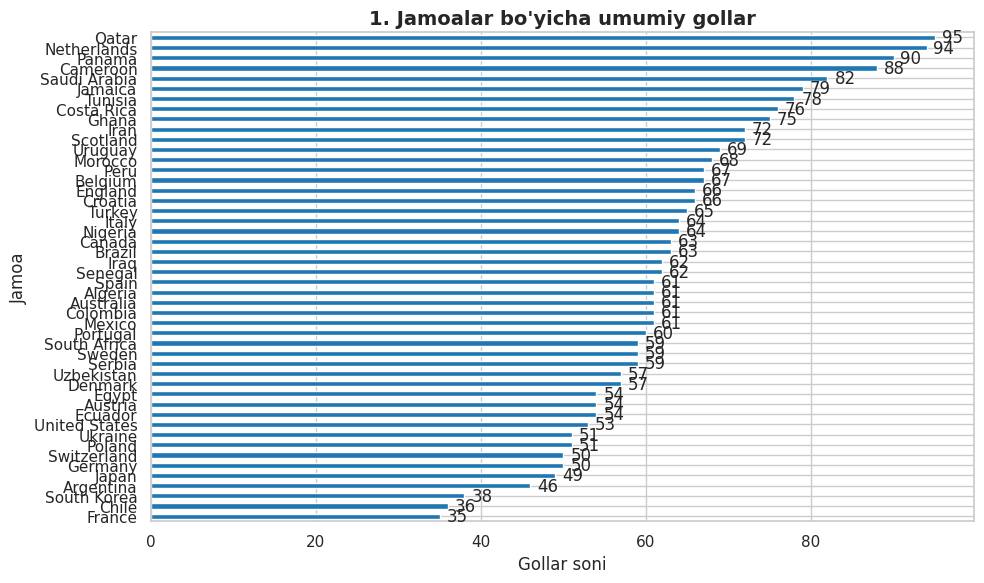

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1-Grafik uchun ma'lumot va hajm
plt.figure(figsize=(10, 6))
groupby_1 = df.groupby('team')['goals'].sum().sort_values(ascending=True)

ax1 = groupby_1.plot(kind='barh', color='#1f77b4')
plt.title("1. Jamoalar bo'yicha umumiy gollar", fontsize=14, fontweight='bold')
plt.xlabel("Gollar soni")
plt.ylabel("Jamoa")

# Ustunga sonlarni (Data Labels) chiqarish
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_width())}",
                 (p.get_width(), p.get_y() + p.get_height() / 2.),
                 ha='left', va='center', xytext=(5, 0), textcoords='offset points')

plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

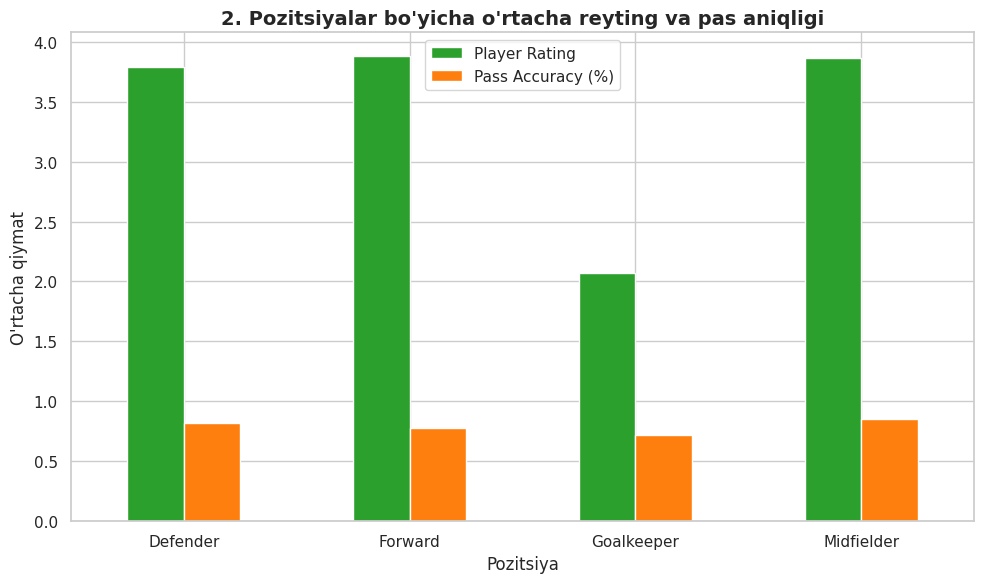

In [50]:
# 2-Grafik uchun ma'lumot va hajm
plt.figure(figsize=(10, 6))
groupby_2 = df.groupby('position')[['player_rating', 'pass_accuracy']].mean()

groupby_2.plot(kind='bar', color=['#2ca02c', '#ff7f0e'], rot=0, figsize=(10, 6))
plt.title("2. Pozitsiyalar bo'yicha o'rtacha reyting va pas aniqligi", fontsize=14, fontweight='bold')
plt.ylabel("O'rtacha qiymat")
plt.xlabel("Pozitsiya")
plt.legend(["Player Rating", "Pass Accuracy (%)"])

plt.tight_layout()
plt.show()

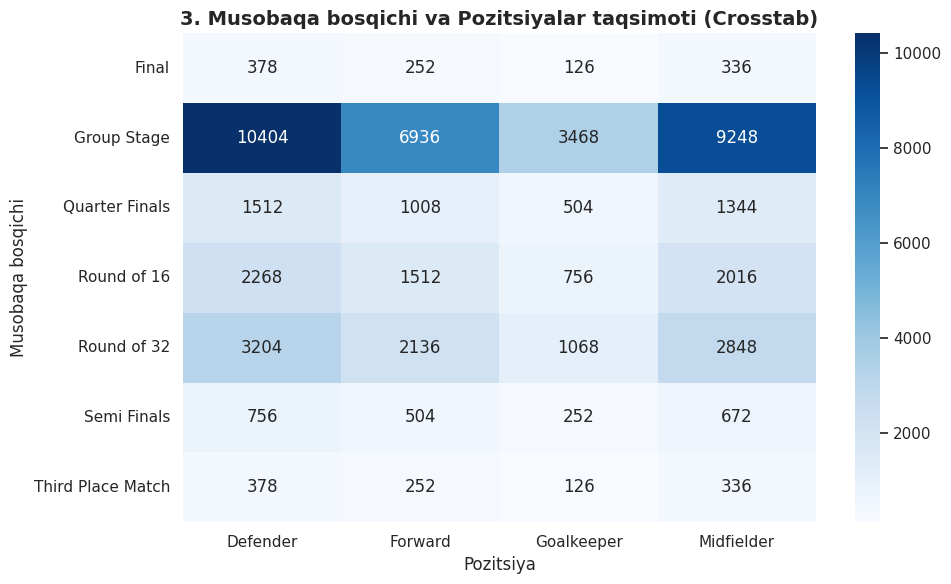

In [51]:
# 3-Grafik uchun ma'lumot va hajm
plt.figure(figsize=(10, 6))
groupby_3 = pd.crosstab(df['tournament_stage'], df['position'])

sns.heatmap(groupby_3, annot=True, fmt="d", cmap="Blues", cbar=True)
plt.title("3. Musobaqa bosqichi va Pozitsiyalar taqsimoti (Crosstab)", fontsize=14, fontweight='bold')
plt.xlabel("Pozitsiya")
plt.ylabel("Musobaqa bosqichi")

plt.tight_layout()
plt.show()